In [1]:
from pathlib import Path
from zipfile import ZipFile
import json
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch_geometric.data import HeteroData
from torch_geometric.nn import HeteroConv, SAGEConv
import torch_geometric.transforms as T
import torch.nn.functional as F
from itertools import combinations
import matplotlib.pyplot as plt

/home/afoek/miniconda3/envs/hackathon/lib/python3.13/site-packages/torch/__config__.py:9: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12050). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._show_config()
/home/afoek/miniconda3/envs/hackathon/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/afoek/miniconda3/envs/hackathon/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `to

# Seed control

In [2]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Variable

In [3]:
ZIP_PATH = Path("qguard_pilot_300.zip")

with ZipFile(ZIP_PATH) as archive:
    archive.extractall(".")

ROOT = Path("qguard_pilot_300/data/pilot")
RAW = ROOT / "raw"
PRIVATE = ROOT / "private"
FEATURES = [
    "log_amount",
    "is_deposit",
    "is_wager",
    "is_withdrawal",
    "is_payout",
    "is_approved",
    "log_gap_hours",
    "hour_sin",
    "hour_cos",
    "is_weekend",
]
MAX_SEQ_LEN = 30
HIDDEN_DIM = 32

# Dataset loader

In [4]:
public = {}

for name in [
    "accounts",
    "transactions",
    "sessions",
    "payment_events",
    "devices",
    "networks",
]:
    public[name] = pd.read_parquet(
        RAW / f"{name}.parquet"
    )

private = {
    "persons": pd.read_parquet(
        PRIVATE / "persons.parquet"
    ),
    "ownership": pd.read_parquet(
        PRIVATE / "ownership.parquet"
    )
}

for name, df in public.items():
    print(f"{name:18s}", df.shape)

print("\nPrivate:")
for name, df in private.items():
    print(f"{name:18s}", df.shape)

accounts           (377, 4)
transactions       (16524, 9)
sessions           (11153, 7)
payment_events     (6554, 6)
devices            (773, 3)
networks           (492, 3)

Private:
persons            (300, 8)
ownership          (377, 2)


In [5]:
accounts = public["accounts"]

account_ids = sorted(
    accounts["account_id"].astype(str).unique()
)

account_to_idx = {
    account_id: i
    for i, account_id in enumerate(account_ids)
}

idx_to_account = {
    i: account_id
    for account_id, i in account_to_idx.items()
}

N_ACCOUNTS = len(account_ids)

print("Accounts:", N_ACCOUNTS)
print(list(account_to_idx.items())[:5])

Accounts: 377
[('A0000000', 0), ('A0000001', 1), ('A0000002', 2), ('A0000003', 3), ('A0000004', 4)]


In [6]:
ownership = private["ownership"]

owner_groups = (
    ownership.groupby("person_id")["account_id"]
    .agg(list)
)

positive_pairs = []

for account_group in owner_groups:
    if len(account_group) < 2:
        continue

    for a, b in combinations(account_group, 2):
        i = account_to_idx[a]
        j = account_to_idx[b]

        positive_pairs.append(
            tuple(sorted((i, j)))
        )

positive_pairs = sorted(set(positive_pairs))

# GRU Inputs

In [7]:
tx = public["transactions"].copy()
tx["timestamp"] = pd.to_datetime(tx["timestamp"], utc=True)
SNAPSHOT = pd.Timestamp("2026-10-01", tz="UTC")
tx = tx[tx["timestamp"] < SNAPSHOT].copy()
tx = tx.sort_values(["account_id", "timestamp", "transaction_id"])
tx["log_amount"] = np.log1p(tx["amount_cad"].clip(lower=0))

for kind in ["deposit", "wager", "withdrawal", "payout"]:
    tx[f"is_{kind}"] = (tx["transaction_type"] == kind).astype(float)

tx["is_approved"] = (tx["status"] == "approved").astype(float)
hours_since_previous = (tx.groupby("account_id")["timestamp"].diff().dt.total_seconds().div(3600).fillna(0).clip(lower=0))
tx["log_gap_hours"] = np.log1p(hours_since_previous)
hour = (tx["timestamp"].dt.hour + tx["timestamp"].dt.minute / 60)
tx["hour_sin"] = np.sin(2 * np.pi * hour / 24)
tx["hour_cos"] = np.cos(2 * np.pi * hour / 24)
tx["is_weekend"] = (tx["timestamp"].dt.dayofweek >= 5).astype(float)

In [8]:
sequences = torch.zeros(
    N_ACCOUNTS,
    MAX_SEQ_LEN,
    len(FEATURES),
    dtype=torch.float32
)

seq_lengths = torch.zeros(
    N_ACCOUNTS,
    dtype=torch.long
)

for account_id, group in tx.groupby("account_id"):
    if account_id not in account_to_idx:
        continue

    idx = account_to_idx[account_id]

    values = (
        group[FEATURES]
        .tail(MAX_SEQ_LEN)
        .to_numpy(dtype=np.float32)
    )

    n = len(values)

    sequences[idx, :n] = torch.from_numpy(values)
    seq_lengths[idx] = n

print("Sequences:", sequences.shape)
print("Lengths:", seq_lengths.shape)
print("Zero-history accounts:", (seq_lengths == 0).sum().item())

assert torch.isfinite(sequences).all()

/tmp/ipykernel_136633/1015019655.py:27: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  sequences[idx, :n] = torch.from_numpy(values)


Sequences: torch.Size([377, 30, 10])
Lengths: torch.Size([377])
Zero-history accounts: 12


# Graph egdes builder

In [9]:
# Load observable relationship events
sessions = public["sessions"].copy()
payments = public["payment_events"].copy()

# Match the snapshot used for transaction preprocessing
SNAPSHOT = pd.Timestamp("2026-10-01", tz="UTC")

sessions["timestamp"] = pd.to_datetime(
    sessions["timestamp"], utc=True
)

payments["timestamp"] = pd.to_datetime(
    payments["timestamp"], utc=True
)

sessions = sessions[
    sessions["timestamp"] < SNAPSHOT
].copy()

payments = payments[
    payments["timestamp"] < SNAPSHOT
].copy()

# Create node lists
node_ids = {
    "account": account_ids,
    "device": sorted(
        public["devices"]["device_id"].dropna().unique()
    ),
    "network": sorted(
        public["networks"]["network_id"].dropna().unique()
    ),
    "payment": sorted(
        payments["payment_token"].dropna().unique()
    ),
}

# Map identifiers to integer indices
node_map = {
    kind: {
        node_id: i
        for i, node_id in enumerate(ids)
    }
    for kind, ids in node_ids.items()
}

for kind, ids in node_ids.items():
    print(f"{kind:10s}: {len(ids)} nodes")

account   : 377 nodes
device    : 773 nodes
network   : 492 nodes
payment   : 412 nodes


In [10]:
graph = HeteroData()

# Placeholder node features for topology testing.
for kind, ids in node_ids.items():
    graph[kind].x = torch.ones(
        len(ids), 1, dtype=torch.float32
    )

def add_relation(frame, target_col, node_type, relation):
    pairs = (
        frame[["account_id", target_col]]
        .dropna()
        .drop_duplicates()
    )

    pairs = pairs[
        pairs["account_id"].isin(node_map["account"])
        & pairs[target_col].isin(node_map[node_type])
    ]

    src = pairs["account_id"].map(
        node_map["account"]
    ).to_numpy(dtype=np.int64)

    dst = pairs[target_col].map(
        node_map[node_type]
    ).to_numpy(dtype=np.int64)

    graph[
        "account", relation, node_type
    ].edge_index = torch.tensor(
        np.stack([src, dst]),
        dtype=torch.long
    )


add_relation(
    sessions, "device_id",
    "device", "uses_device"
)

add_relation(
    sessions, "network_id",
    "network", "connects_from"
)

add_relation(
    payments, "payment_token",
    "payment", "uses_payment"
)

graph = T.ToUndirected()(graph)

print(graph)

assert graph["account"].num_nodes == N_ACCOUNTS
assert sequences.shape[0] == N_ACCOUNTS
assert len(positive_pairs) > 0

print("GRU input:", sequences.shape)
print("Graph nodes:", graph.num_nodes)
print("Graph edges:", graph.num_edges)
print("Same-owner pairs:", len(positive_pairs))
print("Relationship types:", graph.edge_types)

print("Sequences:", sequences.shape)
print("Lengths:", seq_lengths.shape)

print("Feature count:", sequences.shape[-1])
print("Min events:", seq_lengths.min().item())
print("Max events:", seq_lengths.max().item())

assert sequences.ndim == 3
assert seq_lengths.ndim == 1
assert sequences.shape[0] == seq_lengths.shape[0]
assert sequences.shape[1] == 30
assert torch.isfinite(sequences).all()

HeteroData(
  account={ x=[377, 1] },
  device={ x=[773, 1] },
  network={ x=[492, 1] },
  payment={ x=[412, 1] },
  (account, uses_device, device)={ edge_index=[2, 897] },
  (account, connects_from, network)={ edge_index=[2, 1452] },
  (account, uses_payment, payment)={ edge_index=[2, 462] },
  (device, rev_uses_device, account)={ edge_index=[2, 897] },
  (network, rev_connects_from, account)={ edge_index=[2, 1452] },
  (payment, rev_uses_payment, account)={ edge_index=[2, 462] }
)
GRU input: torch.Size([377, 30, 10])
Graph nodes: 2054
Graph edges: 5622
Same-owner pairs: 93
Relationship types: [('account', 'uses_device', 'device'), ('account', 'connects_from', 'network'), ('account', 'uses_payment', 'payment'), ('device', 'rev_uses_device', 'account'), ('network', 'rev_connects_from', 'account'), ('payment', 'rev_uses_payment', 'account')]
Sequences: torch.Size([377, 30, 10])
Lengths: torch.Size([377])
Feature count: 10
Min events: 0
Max events: 30


# Temporal GRU

In [11]:
class TemporalGRU(nn.Module):
    def __init__(self, input_dim, hidden_dim=32):
        super().__init__()
        self.gru = nn.GRU(input_size=input_dim, hidden_size=hidden_dim, num_layers=1, batch_first=True)
        self.norm = nn.LayerNorm(hidden_dim)
        
    def forward(self, x, lengths):
        packed = pack_padded_sequence(x, lengths.clamp_min(1).cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.gru(packed)
        h = self.norm(hidden[-1])
        # Accounts without transactions get zero embeddings.
        h = h.masked_fill((lengths == 0).to(h.device).unsqueeze(1), 0.0)
        return h

## Sanity check

In [12]:
INPUT_DIM = sequences.shape[-1]
temporal_model = TemporalGRU(input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM)
print(temporal_model)

print(
    "Trainable parameters:",
    sum(p.numel() for p in temporal_model.parameters())
)

temporal_model.eval()
with torch.no_grad():
    temporal_embeddings = temporal_model(sequences, seq_lengths)

print("Input:", sequences.shape)
print("Output:", temporal_embeddings.shape)

assert temporal_embeddings.shape == (
    sequences.shape[0],
    HIDDEN_DIM
)

assert torch.isfinite(temporal_embeddings).all()

account_idx = 0

print("Account:", idx_to_account[account_idx])
print("Transactions:", seq_lengths[account_idx].item())

print("\nTemporal embedding:")
print(temporal_embeddings[account_idx])

temporal_model.train()
temporal_model.zero_grad()

embeddings = temporal_model(
    sequences[:16],
    seq_lengths[:16]
)

test_loss = embeddings.square().mean()

test_loss.backward()

print("Test loss:", test_loss.item())

print(
    "GRU gradient norm:",
    temporal_model.gru.weight_ih_l0.grad.norm().item()
)

TemporalGRU(
  (gru): GRU(10, 32, batch_first=True)
  (norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
)
Trainable parameters: 4288
Input: torch.Size([377, 30, 10])
Output: torch.Size([377, 32])
Account: A0000000
Transactions: 25

Temporal embedding:
tensor([ 0.3846,  1.5818, -1.0520,  0.5723,  0.3555,  1.3580,  0.8305,  0.8240,
         0.1748, -0.3616,  0.9417, -0.2856, -0.4920, -0.3685, -0.4174, -0.7731,
        -1.3867, -0.9242,  0.5580,  0.4450,  0.1219,  1.2345,  1.1219,  0.1908,
         1.9121, -0.2452,  0.7506, -1.0961, -1.9082, -0.4053, -1.4638, -2.1782])
Test loss: 0.9999004602432251
GRU gradient norm: 0.00024505905457772315


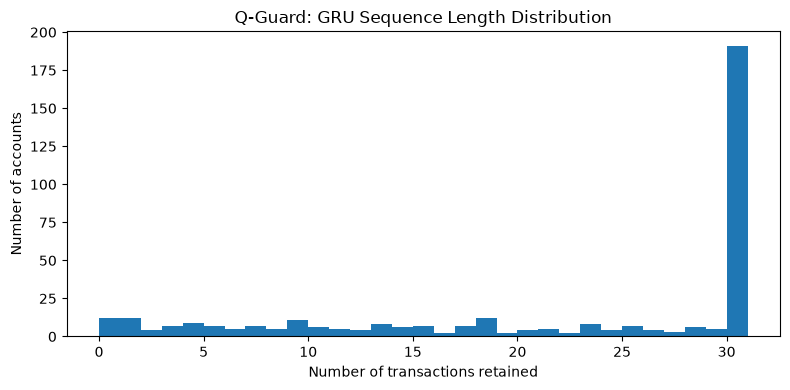

In [13]:
plt.figure(figsize=(8, 4))

plt.hist(
    seq_lengths.numpy(),
    bins=range(0, 32)
)

plt.xlabel("Number of transactions retained")
plt.ylabel("Number of accounts")
plt.title("Q-Guard: GRU Sequence Length Distribution")

plt.tight_layout()
plt.show()

In [14]:
print("Node types:", graph.node_types)
print("\nEdge types:")

for edge_type in graph.edge_types:
    print(edge_type, graph[edge_type].edge_index.shape)

required_edges = [
    ("account", "uses_device", "device"),
    ("account", "connects_from", "network"),
    ("account", "uses_payment", "payment"),
    ("device", "rev_uses_device", "account"),
    ("network", "rev_connects_from", "account"),
    ("payment", "rev_uses_payment", "account"),
]

for relation in required_edges:
    assert relation in graph.edge_types, (
        f"Missing relationship: {relation}"
    )

assert graph["account"].num_nodes == N_ACCOUNTS

print("Graph validation PASSED")

Node types: ['account', 'device', 'network', 'payment']

Edge types:
('account', 'uses_device', 'device') torch.Size([2, 897])
('account', 'connects_from', 'network') torch.Size([2, 1452])
('account', 'uses_payment', 'payment') torch.Size([2, 462])
('device', 'rev_uses_device', 'account') torch.Size([2, 897])
('network', 'rev_connects_from', 'account') torch.Size([2, 1452])
('payment', 'rev_uses_payment', 'account') torch.Size([2, 462])
Graph validation PASSED


In [15]:
# Use the same snapshot as Step 2.
s = public["sessions"].copy()
p = public["payment_events"].copy()

s["timestamp"] = pd.to_datetime(
    s["timestamp"], utc=True
)

p["timestamp"] = pd.to_datetime(
    p["timestamp"], utc=True
)

s = s[
    (s["timestamp"] < SNAPSHOT)
    & s["account_id"].isin(account_to_idx)
].copy()

p = p[
    (p["timestamp"] < SNAPSHOT)
    & p["account_id"].isin(account_to_idx)
].copy()

In [16]:
def account_counts(df, column=None):
    grouped = df.groupby("account_id")

    if column is None:
        counts = grouped.size()
    else:
        counts = grouped[column].nunique()

    return (
        counts.reindex(account_ids, fill_value=0)
        .to_numpy(dtype=np.float32)
    )

In [17]:
account_features = np.column_stack([
    account_counts(s),
    account_counts(s, "device_id"),
    account_counts(s, "network_id"),
    account_counts(p),
    account_counts(p, "payment_token"),
])

account_features = np.log1p(account_features)

graph["account"].x = torch.tensor(
    account_features,
    dtype=torch.float32
)

print("Account features:", graph["account"].x.shape)

Account features: torch.Size([377, 5])


In [18]:
def resource_features(df, column, ids):
    grouped = df.groupby(column)

    event_count = grouped.size()
    account_count = grouped["account_id"].nunique()

    event_count = event_count.reindex(
        ids, fill_value=0
    ).to_numpy(dtype=np.float32)

    account_count = account_count.reindex(
        ids, fill_value=0
    ).to_numpy(dtype=np.float32)

    return torch.tensor(
        np.column_stack([
            np.ones(len(ids), dtype=np.float32),
            np.log1p(event_count),
            np.log1p(account_count),
        ]),
        dtype=torch.float32
    )


graph["device"].x = resource_features(
    s, "device_id", node_ids["device"]
)

graph["network"].x = resource_features(
    s, "network_id", node_ids["network"]
)

graph["payment"].x = resource_features(
    p, "payment_token", node_ids["payment"]
)

for kind in graph.node_types:
    print(kind, graph[kind].x.shape)

account torch.Size([377, 5])
device torch.Size([773, 3])
network torch.Size([492, 3])
payment torch.Size([412, 3])


# HeteroSAGE

In [19]:
class HeteroGraphSAGE(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()

        # Stage 1: Account -> Resources
        self.to_resources = HeteroConv({
            ("account", "uses_device", "device"):
                SAGEConv((-1, -1), hidden_dim),

            ("account", "connects_from", "network"):
                SAGEConv((-1, -1), hidden_dim),

            ("account", "uses_payment", "payment"):
                SAGEConv((-1, -1), hidden_dim),
        }, aggr="sum")

        # Stage 2: Resources -> Account
        self.to_accounts = HeteroConv({
            ("device", "rev_uses_device", "account"):
                SAGEConv((-1, -1), hidden_dim),

            ("network", "rev_connects_from", "account"):
                SAGEConv((-1, -1), hidden_dim),

            ("payment", "rev_uses_payment", "account"):
                SAGEConv((-1, -1), hidden_dim),
        }, aggr="sum")

        self.skip = nn.Linear(5, hidden_dim)
        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, graph):
        # Account information flows to resource nodes.
        resource_h = self.to_resources(
            graph.x_dict,
            graph.edge_index_dict
        )

        resource_x = {
            "account": graph["account"].x,
            "device": F.relu(resource_h["device"]),
            "network": F.relu(resource_h["network"]),
            "payment": F.relu(resource_h["payment"]),
        }

        # Resource information flows back to accounts.
        account_h = self.to_accounts(
            resource_x,
            graph.edge_index_dict
        )["account"]

        # Residual path preserves original account features.
        account_h = account_h + self.skip(
            graph["account"].x
        )

        return self.norm(F.relu(account_h))

## Sanity checks

In [20]:
graph_model = HeteroGraphSAGE(hidden_dim=32)

print(graph_model)

HeteroGraphSAGE(
  (to_resources): HeteroConv(num_relations=3)
  (to_accounts): HeteroConv(num_relations=3)
  (skip): Linear(in_features=5, out_features=32, bias=True)
  (norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
)


/tmp/ipykernel_136633/1448951117.py:6: UserWarning: There exist node types ({'account'}) whose representations do not get updated during message passing as they do not occur as destination type in any edge type. This may lead to unexpected behavior.
  self.to_resources = HeteroConv({
/tmp/ipykernel_136633/1448951117.py:18: UserWarning: There exist node types ({'device', 'network', 'payment'}) whose representations do not get updated during message passing as they do not occur as destination type in any edge type. This may lead to unexpected behavior.
  self.to_accounts = HeteroConv({


In [21]:
graph_model.eval()

with torch.no_grad():
    graph_embeddings = graph_model(graph)

print("GNN output:", graph_embeddings.shape)

assert graph_embeddings.shape == (
    N_ACCOUNTS, 32
)

assert torch.isfinite(graph_embeddings).all()

print(
    "Mean embedding variation:",
    graph_embeddings.std(dim=0).mean().item()
)

GNN output: torch.Size([377, 32])
Mean embedding variation: 0.13898472487926483


In [22]:
graph_model.train()
graph_model.zero_grad()

outputs = graph_model(graph)

probe = torch.randn_like(outputs)

test_loss = (outputs * probe).mean()
test_loss.backward()

grad_norms = [
    param.grad.norm().item()
    for param in graph_model.parameters()
    if param.grad is not None
]

print("Test loss:", test_loss.item())
print("Total gradient norm:", sum(grad_norms))

assert len(grad_norms) > 0
assert all(np.isfinite(v) for v in grad_norms)
assert sum(grad_norms) > 0

Test loss: 0.011615456081926823
Total gradient norm: 0.21831575687974691


In [23]:
print("Temporal:", temporal_embeddings.shape)
print("Graph:", graph_embeddings.shape)

assert (
    temporal_embeddings.shape
    == graph_embeddings.shape
)

# Concatenate embeddings for the future fusion layer.
combined_embeddings = torch.cat(
    [temporal_embeddings, graph_embeddings],
    dim=1
)

print("Combined:", combined_embeddings.shape)

Temporal: torch.Size([377, 32])
Graph: torch.Size([377, 32])
Combined: torch.Size([377, 64])


# Classical Fusion

In [24]:
class ClassicalFusion(nn.Module):
    def __init__(self, input_dim=64, hidden_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.LayerNorm(hidden_dim)
        )

    def forward(self, temporal_h, graph_h):
        combined = torch.cat([temporal_h, graph_h], dim=-1)

        return self.net(combined)

In [25]:
fusion = ClassicalFusion(
    input_dim=64,
    hidden_dim=32
)

fusion.eval()

with torch.no_grad():
    fused_embeddings = fusion(
        temporal_embeddings,
        graph_embeddings
    )

print("Temporal:", temporal_embeddings.shape)
print("Graph:", graph_embeddings.shape)
print("Fused:", fused_embeddings.shape)

Temporal: torch.Size([377, 32])
Graph: torch.Size([377, 32])
Fused: torch.Size([377, 32])


# Account Pair Decoder

In [26]:
class AccountPairDecoder(nn.Module):
    def __init__(self, embed_dim=32):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(embed_dim * 2, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, embeddings, pair_index):
        idx_a = pair_index[0]
        idx_b = pair_index[1]

        h_a = embeddings[idx_a]
        h_b = embeddings[idx_b]

        pair_features = torch.cat([
            torch.abs(h_a - h_b),
            h_a * h_b
        ], dim=-1)

        return self.classifier(
            pair_features
        ).squeeze(-1)

# Classical Fusion Model

In [27]:
class QGuardClassical(nn.Module):
    def __init__(self, temporal, graph_encoder):
        super().__init__()

        self.temporal = temporal
        self.graph_encoder = graph_encoder

        self.fusion = ClassicalFusion(
            input_dim=64,
            hidden_dim=32
        )

        self.decoder = AccountPairDecoder(
            embed_dim=32
        )

    def forward(self, sequences, lengths, graph, pairs):
        h_t = self.temporal(sequences, lengths)
        h_g = self.graph_encoder(graph)

        h_f = self.fusion(h_t, h_g)

        logits = self.decoder(h_f, pairs)

        return logits

In [28]:
model = QGuardClassical(
    temporal=temporal_model,
    graph_encoder=graph_model
)

# Three arbitrary account pairs for testing shapes only.
test_pairs = torch.tensor([
    [0, 0, 1],
    [1, 2, 2]
], dtype=torch.long)

model.eval()

with torch.no_grad():
    logits = model(
        sequences,
        seq_lengths,
        graph,
        test_pairs
    )

    probabilities = torch.sigmoid(logits)

print("Logits:", logits.shape)
print("Probabilities:", probabilities)

Logits: torch.Size([3])
Probabilities: tensor([0.5986, 0.6032, 0.5914])


In [29]:
model.train()
model.zero_grad()

logits = model(
    sequences,
    seq_lengths,
    graph,
    test_pairs
)

# Artificial gradient test, not a supervised loss.
test_loss = logits.square().mean()
test_loss.backward()

for name, module in [
    ("Temporal GRU", model.temporal),
    ("GraphSAGE", model.graph_encoder),
    ("Fusion", model.fusion),
    ("Decoder", model.decoder),
]:
    grads = [
        p.grad.norm().item()
        for p in module.parameters()
        if p.grad is not None
    ]

    print(
        f"{name:15s}:",
        sum(grads)
    )

Temporal GRU   : 1.68636005371809
GraphSAGE      : 1.9732171911746264
Fusion         : 2.7119227945804596
Decoder        : 6.860761106014252


In [30]:
ownership = private["ownership"].copy()
persons = private["persons"].copy()

owner_by_account = (
    ownership.set_index("account_id")["person_id"]
    .to_dict()
)

assert ownership["account_id"].is_unique
assert set(account_ids) == set(owner_by_account)

print("Accounts:", len(owner_by_account))
print("Unique people:", ownership["person_id"].nunique())

Accounts: 377
Unique people: 300


In [31]:
owner_groups = (
    ownership.groupby("person_id")["account_id"]
    .agg(list)
)

positive_pairs = set()

for group in owner_groups:
    for a, b in combinations(group, 2):
        i = account_to_idx[a]
        j = account_to_idx[b]

        positive_pairs.add(
            tuple(sorted((i, j)))
        )

positive_pairs = sorted(positive_pairs)

print("Positive pairs:", len(positive_pairs))

Positive pairs: 93


In [32]:
meta = ownership.merge(
    persons[["person_id", "household_id"]],
    on="person_id",
    validate="many_to_one"
)

hard_negative_pairs = set()

for _, group in meta.groupby("household_id"):
    members = group["account_id"].tolist()

    for a, b in combinations(members, 2):
        if owner_by_account[a] == owner_by_account[b]:
            continue

        i = account_to_idx[a]
        j = account_to_idx[b]

        hard_negative_pairs.add(
            tuple(sorted((i, j)))
        )

hard_negative_pairs = sorted(hard_negative_pairs)

print("Household hard negatives:",
      len(hard_negative_pairs))

Household hard negatives: 224


In [33]:
rng = np.random.default_rng(42)

n_positive = len(positive_pairs)
n_negative = 3 * n_positive

n_hard = min(
    len(hard_negative_pairs),
    n_negative // 2
)

negatives = set()

if n_hard > 0:
    chosen = rng.choice(
        len(hard_negative_pairs),
        size=n_hard,
        replace=False
    )

    negatives.update(
        hard_negative_pairs[i]
        for i in chosen
    )

positive_set = set(positive_pairs)

while len(negatives) < n_negative:
    i, j = rng.choice(
        N_ACCOUNTS, size=2, replace=False
    )

    pair = tuple(sorted((int(i), int(j))))

    if pair not in positive_set:
        negatives.add(pair)

pairs = positive_pairs + sorted(negatives)

labels = (
    [1.0] * len(positive_pairs)
    + [0.0] * len(negatives)
)

order = rng.permutation(len(pairs))

pair_index = torch.tensor(
    np.asarray(pairs, dtype=np.int64)[order].T,
    dtype=torch.long
)

pair_targets = torch.tensor(
    np.asarray(labels, dtype=np.float32)[order]
)

print("Pairs:", pair_index.shape)
print("Targets:", pair_targets.shape)
print("Positive:", int(pair_targets.sum().item()))
print("Negative:", int((pair_targets == 0).sum().item()))

Pairs: torch.Size([2, 372])
Targets: torch.Size([372])
Positive: 93
Negative: 279


In [34]:
assert pair_index.shape[0] == 2
assert pair_index.shape[1] == len(pair_targets)

assert (pair_index[0] != pair_index[1]).all()
assert (pair_index < N_ACCOUNTS).all()
assert (pair_index >= 0).all()

for k in range(len(pair_targets)):
    i, j = pair_index[:, k].tolist()

    a = idx_to_account[i]
    b = idx_to_account[j]

    expected = float(
        owner_by_account[a] == owner_by_account[b]
    )

    assert pair_targets[k].item() == expected

print("PAIR LABEL VALIDATION PASSED")

PAIR LABEL VALIDATION PASSED
